# RQ4 Classification: SVM · CART · KNN · Naïve Bayes · Majority Voting



### Imports & Configuration

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats

# ── sklearn ─────────────────────────────────────────────────
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, cross_val_predict
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Classifiers
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier

# Metrics
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc, roc_auc_score,
    balanced_accuracy_score
)

# ── colour palette ───────────────────────────────────────────
PALETTE = {'ASD': '#E05C2A', 'Control': '#2A7AE0'}
DX_MAP  = {1: 'ASD', 2: 'Control'}

RANDOM_STATE = 42
N_SPLITS     = 5        # stratified k-fold for CV
TEST_SIZE    = 0.20     # held-out test fraction

print('All imports successful.')

All imports successful.


---
## Block 1 — Load Data & Strict Train / Test Split


In [44]:
from neuroCombat import neuroCombat
# ── Load harmonised data ─────────────────────────────────────
df = pd.read_csv('abide_merged.csv')
df.replace(-9999, np.nan, inplace=True)
# 1. Prepare data matrix (Features x Subjects)
df_clean = df 
# ComBat expects the data to be transposed (columns are patients, rows are brain regions)
brain_data = df_clean[THICKNESS_COLS].T

# 2. Prepare covariates (The biological stuff to PROTECT)
# We must protect the diagnosis, and it's best to protect Age and Sex too.
covars = df_clean[['SITE_ID', 'DX_LABEL', 'AGE_AT_SCAN', 'SEX_LABEL']].copy()

# ComBat requires categorical variables to be dummy-coded (0s and 1s)
covars['DX_LABEL'] = covars['DX_LABEL'].map({'ASD': 1, 'Control': 0})
covars['SEX_LABEL'] = covars['SEX_LABEL'].map({'Male': 1, 'Female': 0})

# 3. Run ComBat!
# We tell it what the 'batch' is (the scanner site) 
# We tell it what the 'continuous' (age) and 'categorical' (diagnosis, sex) variables are
harmonised = neuroCombat(dat=brain_data,
                         covars=covars,
                         batch_col='SITE_ID',
                         categorical_cols=['DX_LABEL', 'SEX_LABEL'],
                         continuous_cols=['AGE_AT_SCAN'])

# 4. Extract the clean data and put it back into dataframe
# neuroCombat returns a dictionary. The 'data' key holds the harmonised matrix.
harmonised_data = harmonised['data'].T 

# Create a new dataframe with the clean data
df_harmonised = df_clean.copy()
df_harmonised[THICKNESS_COLS] = harmonised_data

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data


In [45]:


# Ensure DX_LABEL exists
if 'DX_LABEL' not in df.columns:
    df['DX_LABEL'] = df['DX_GROUP'].map(DX_MAP)

# Identify the 68 thickness columns
THICKNESS_COLS = [c for c in df.columns if c.startswith(('lh_', 'rh_'))]
print(f'Loaded: {df.shape[0]} subjects | {len(THICKNESS_COLS)} thickness regions')
print(f'ASD: {(df.DX_GROUP==1).sum()} | Control: {(df.DX_GROUP==2).sum()}')
print(f'Sites: {df.SITE_ID.nunique()}')
print()

# ── Drop rows with any missing thickness ─────────────────────
df_complete = df.dropna(subset=THICKNESS_COLS).reset_index(drop=True)
print(f'After dropping missing: {len(df_complete)} subjects')

# Ensure SEX column exists, then create a 3-way stratification key: diagnosis × site × sex
strat_key = (df_complete['DX_GROUP'].astype(str) + '_' + 
             df_complete['SITE_ID'].astype(str) + '_' + 
             df_complete['SEX'].astype(str))

# Remove strata with only 1 member (can't stratify split)
strat_counts = strat_key.value_counts()
valid_mask   = strat_key.isin(strat_counts[strat_counts >= 2].index)
df_complete  = df_complete[valid_mask].reset_index(drop=True)
strat_key    = strat_key[valid_mask].reset_index(drop=True)
print(f'After removing singleton strata: {len(df_complete)} subjects')

# ── Train / Test split ───────────────────────────────────────
idx_all   = np.arange(len(df_complete))
idx_train, idx_test = train_test_split(
    idx_all,
    test_size    = TEST_SIZE,
    random_state = RANDOM_STATE,
    stratify     = strat_key
)

df_train = df_complete.iloc[idx_train].reset_index(drop=True)
df_test  = df_complete.iloc[idx_test ].reset_index(drop=True)

print(f'\nTrain: {len(df_train)} subjects '
      f'(ASD={( df_train.DX_GROUP==1).sum()}, '
      f'Control={(df_train.DX_GROUP==2).sum()})')
print(f'Test : {len(df_test)} subjects '
      f'(ASD={(df_test.DX_GROUP==1).sum()}, '
      f'Control={(df_test.DX_GROUP==2).sum()})')
print()
print('Sites in train:', sorted(df_train.SITE_ID.unique()))
print('Sites in test :', sorted(df_test.SITE_ID.unique()))
print()
print('🔒 df_test is now sealed. It will NOT be accessed again until Block 9.')

Loaded: 1035 subjects | 68 thickness regions
ASD: 505 | Control: 530
Sites: 20

After dropping missing: 1027 subjects
After removing singleton strata: 1023 subjects

Train: 818 subjects (ASD=398, Control=420)
Test : 205 subjects (ASD=99, Control=106)

Sites in train: ['CALTECH', 'CMU', 'KKI', 'LEUVEN_1', 'LEUVEN_2', 'MAX_MUN', 'NYU', 'OHSU', 'OLIN', 'PITT', 'SBL', 'SDSU', 'STANFORD', 'TRINITY', 'UCLA_1', 'UCLA_2', 'UM_1', 'UM_2', 'USM', 'YALE']
Sites in test : ['CALTECH', 'CMU', 'KKI', 'LEUVEN_1', 'LEUVEN_2', 'MAX_MUN', 'NYU', 'OHSU', 'OLIN', 'PITT', 'SBL', 'SDSU', 'STANFORD', 'TRINITY', 'UCLA_1', 'UCLA_2', 'UM_1', 'UM_2', 'USM', 'YALE']

🔒 df_test is now sealed. It will NOT be accessed again until Block 9.


---
## Block 2 — Feature Sets

We use two feature sets throughout:
- **F68**: all 68 Desikan-Killiany cortical thickness regions  
- **F8**: the 8 regions confirmed significant in RQ1 after FDR correction on ComBat-harmonised data

In [46]:
# ── 8 regions confirmed significant post-harmonisation (from RQ1) ────────────
CONFIRMED_8 = [
    'lh_lateraloccipital',
    'rh_lateraloccipital',
    'lh_lingual',
    'rh_lingual',
    'lh_cuneus',
    'lh_entorhinal',
    'lh_medialorbitofrontal',
    'lh_pericalcarine'
]

# Verify all 8 are present in the data
CONFIRMED_8 = [c for c in CONFIRMED_8 if c in THICKNESS_COLS]
print(f'Confirmed 8 regions found in data: {len(CONFIRMED_8)}')

FEATURE_SETS = {
    'F8_confirmed' : CONFIRMED_8,
    'F68_all'      : THICKNESS_COLS,
}

# Extract matrices
y_train = df_train['DX_GROUP'].values   # 1=ASD, 2=Control
y_test  = df_test['DX_GROUP'].values

X_train_sets = {name: df_train[cols].values for name, cols in FEATURE_SETS.items()}
X_test_sets  = {name: df_test [cols].values for name, cols in FEATURE_SETS.items()}

print('\nFeature set shapes (train):')
for name, X in X_train_sets.items():
    print(f'  {name}: {X.shape}')

Confirmed 8 regions found in data: 8

Feature set shapes (train):
  F8_confirmed: (818, 8)
  F68_all: (818, 68)


---
## Block 3 — Preprocessing Pipeline

**Rule**: `StandardScaler` is **fit on training data only**.  
It is embedded inside each `Pipeline` below so that `GridSearchCV`
and `cross_validate` automatically refit the scaler on each fold's training portion,
preventing leakage of test statistics into training.

Using `sklearn.pipeline.Pipeline` is the standard anti-leakage pattern:
every fold's scaler learns mean/std from that fold's training subset,
not from validation or test data.

In [47]:
# Helper: build a pipeline with StandardScaler + any estimator
def make_pipe(estimator):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('clf',    estimator)
    ])

# Cross-validation strategy — stratified by diagnosis
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# Scoring metrics computed during CV
SCORING = {
    'accuracy'  : 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'roc_auc'   : 'roc_auc',
    'f1'        : 'f1',          # F1 for ASD (positive class = 1)
    'sensitivity': 'recall',     # recall = sensitivity for ASD
}

# Helper: summarise cross_validate output
def summarise_cv(cv_results, name=''):
    row = {'model': name}
    for metric in ['test_accuracy', 'test_balanced_accuracy', 'test_roc_auc',
                   'test_f1', 'test_sensitivity']:
        key = metric.replace('test_', '')
        scores = cv_results[metric]
        row[f'{key}_mean'] = scores.mean()
        row[f'{key}_std']  = scores.std()
    return row

print('Preprocessing pipeline helpers ready.')
print(f'CV strategy: {N_SPLITS}-fold stratified (TRAIN set only)')

Preprocessing pipeline helpers ready.
CV strategy: 5-fold stratified (TRAIN set only)


In [48]:
# ── Block 2 & 3 Combined: Feature Sets & PCA Preprocessing Pipeline ────────────
from sklearn.decomposition import PCA

# Since we are reducing 68 columns down to 20, we only need the full 68-feature set
FEATURE_SETS = {
    'F68_PCA20': THICKNESS_COLS
}

# Extract matrices
y_train = df_train['DX_GROUP'].values   # 1=ASD, 2=Control
y_test  = df_test['DX_GROUP'].values

X_train_sets = {name: df_train[cols].values for name, cols in FEATURE_SETS.items()}
X_test_sets  = {name: df_test [cols].values for name, cols in FEATURE_SETS.items()}

print('\\nFeature set shapes (train) before PCA:')
for name, X in X_train_sets.items():
    print(f'  {name}: {X.shape}')

# ── Preprocessing Pipeline ─────────────────────────────────────────────────────

# Helper: build a pipeline with StandardScaler + PCA (20 components) + estimator
def make_pipe(estimator):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=20, random_state=RANDOM_STATE)), # Reduces features to 20
        ('clf',    estimator)
    ])

# Cross-validation strategy — stratified by diagnosis
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# Scoring metrics computed during CV
SCORING = {
    'accuracy'  : 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'roc_auc'   : 'roc_auc',
    'f1'        : 'f1',          # F1 for ASD (positive class = 1)
    'sensitivity': 'recall',     # recall = sensitivity for ASD
}

print('\\nPreprocessing pipeline helpers ready.')
print('Pipeline sequence: StandardScaler -> PCA (20 components) -> Classifier')
print(f'CV strategy: {N_SPLITS}-fold stratified (TRAIN set only)')

\nFeature set shapes (train) before PCA:
  F68_PCA20: (818, 68)
\nPreprocessing pipeline helpers ready.
Pipeline sequence: StandardScaler -> PCA (20 components) -> Classifier
CV strategy: 5-fold stratified (TRAIN set only)


---
## Block 4 — Support Vector Machine (SVM)

We evaluate two kernels:
- **Linear SVM** (`kernel='linear'`): interpretable, appropriate when features > samples.  
- **RBF SVM** (`kernel='rbf'`): captures non-linear boundaries at the cost of interpretability.

Regularisation `C` is tuned via **GridSearchCV on the training set** using `cv` defined in Block 3.  
Final hyperparameters are recorded; test evaluation is deferred to Block 9.

In [49]:
from sklearn.model_selection import GridSearchCV

cv_results_svm = {}   # store CV results per (kernel, feature_set)
best_pipes_svm = {}   # store best fitted pipelines for Block 9

param_grid_linear = {'clf__C': [0.001, 0.01, 0.1, 1, 10, 100]}
param_grid_rbf    = {'clf__C': [0.01, 0.1, 1, 10, 100],
                     'clf__gamma': ['scale', 'auto', 0.001, 0.01]}

for feat_name, X_tr in X_train_sets.items():
    print(f'\n=== SVM — Feature set: {feat_name} ({X_tr.shape[1]} features) ===')

    for kernel, param_grid in [('linear', param_grid_linear),
                                ('rbf',    param_grid_rbf)]:
        key = f'SVM_{kernel}_{feat_name}'

        pipe = make_pipe(SVC(
            kernel       = kernel,
            probability  = True,      # needed for ROC / voting
            class_weight = 'balanced', # account for slight ASD/Control imbalance
            random_state = RANDOM_STATE
        ))

        # Grid search CV — runs entirely on X_tr / y_train
        gs = GridSearchCV(
            pipe, param_grid,
            cv      = cv,
            scoring = 'roc_auc',
            n_jobs  = -1,
            refit   = True       # refit best model on full X_tr
        )
        gs.fit(X_tr, y_train)

        best_params = gs.best_params_
        best_score  = gs.best_score_

        # Cross-validate best pipeline to get multi-metric CV summary
        cv_res = cross_validate(
            gs.best_estimator_,
            X_tr, y_train,
            cv      = cv,
            scoring = SCORING,
            return_train_score = False
        )

        cv_results_svm[key] = cv_res
        best_pipes_svm[key] = gs.best_estimator_

        print(f'  Kernel={kernel} | Best params: {best_params}')
        print(f'  CV AUC  : {cv_res["test_roc_auc"].mean():.3f} ± {cv_res["test_roc_auc"].std():.3f}')
        print(f'  CV Acc  : {cv_res["test_accuracy"].mean():.3f} ± {cv_res["test_accuracy"].std():.3f}')
        print(f'  CV Bal  : {cv_res["test_balanced_accuracy"].mean():.3f} ± {cv_res["test_balanced_accuracy"].std():.3f}')
        print(f'  CV Sens : {cv_res["test_sensitivity"].mean():.3f} ± {cv_res["test_sensitivity"].std():.3f}')

print('\n✅ SVM block complete. best_pipes_svm filled for Block 9.')


=== SVM — Feature set: F68_PCA20 (68 features) ===
  Kernel=linear | Best params: {'clf__C': 0.01}
  CV AUC  : 0.550 ± 0.032
  CV Acc  : 0.536 ± 0.031
  CV Bal  : 0.531 ± 0.031
  CV Sens : 0.369 ± 0.071
  Kernel=rbf | Best params: {'clf__C': 10, 'clf__gamma': 0.01}
  CV AUC  : 0.573 ± 0.037
  CV Acc  : 0.559 ± 0.028
  CV Bal  : 0.556 ± 0.028
  CV Sens : 0.465 ± 0.022

✅ SVM block complete. best_pipes_svm filled for Block 9.


---
## Block 5 — CART (Decision Tree)

CART grows a binary decision tree. Key hyperparameter: `max_depth` (controls overfitting).  
The tree is interpretable — we can visualise the splits for the F8 feature set.

In [50]:
cv_results_cart = {}
best_pipes_cart = {}

param_grid_cart = {
    'clf__max_depth'       : [3, 4, 5, 6, 8, None],
    'clf__min_samples_leaf': [5, 10, 15, 20],
    'clf__criterion'       : ['gini', 'entropy']
}

for feat_name, X_tr in X_train_sets.items():
    key = f'CART_{feat_name}'

    pipe = make_pipe(DecisionTreeClassifier(
        class_weight = 'balanced',
        random_state = RANDOM_STATE
    ))

    gs = GridSearchCV(
        pipe, param_grid_cart,
        cv      = cv,
        scoring = 'roc_auc',
        n_jobs  = -1,
        refit   = True
    )
    gs.fit(X_tr, y_train)

    cv_res = cross_validate(
        gs.best_estimator_, X_tr, y_train,
        cv=cv, scoring=SCORING, return_train_score=False
    )

    cv_results_cart[key] = cv_res
    best_pipes_cart[key] = gs.best_estimator_

    print(f'CART — {feat_name}')
    print(f'  Best params : {gs.best_params_}')
    print(f'  CV AUC  : {cv_res["test_roc_auc"].mean():.3f} ± {cv_res["test_roc_auc"].std():.3f}')
    print(f'  CV Acc  : {cv_res["test_accuracy"].mean():.3f} ± {cv_res["test_accuracy"].std():.3f}')
    print(f'  CV Bal  : {cv_res["test_balanced_accuracy"].mean():.3f} ± {cv_res["test_balanced_accuracy"].std():.3f}')
    print(f'  CV Sens : {cv_res["test_sensitivity"].mean():.3f} ± {cv_res["test_sensitivity"].std():.3f}')
    print()

# ── Visualise the best CART tree for F8 ─────────────────────
if 'CART_F8_confirmed' in best_pipes_cart:
    tree_clf = best_pipes_cart['CART_F8_confirmed'].named_steps['clf']
    depth    = tree_clf.get_depth()
    print(f'Best CART tree (F8) depth: {depth}')

    fig, ax = plt.subplots(figsize=(max(14, depth * 4), max(6, depth * 2)))
    plot_tree(
        tree_clf,
        feature_names = CONFIRMED_8,
        class_names   = ['ASD', 'Control'],
        filled        = True,
        rounded       = True,
        fontsize      = 8,
        ax            = ax
    )
    ax.set_title(f'CART Tree — F8 Confirmed Regions (depth={depth})', fontsize=12)
    plt.tight_layout()
    plt.savefig('cart_tree_F8.png', dpi=130, bbox_inches='tight')
    plt.show()

print('✅ CART block complete.')

CART — F68_PCA20
  Best params : {'clf__criterion': 'gini', 'clf__max_depth': None, 'clf__min_samples_leaf': 20}
  CV AUC  : 0.553 ± 0.022
  CV Acc  : 0.543 ± 0.023
  CV Bal  : 0.543 ± 0.022
  CV Sens : 0.563 ± 0.061

✅ CART block complete.


---
## Block 6 — K-Nearest Neighbours (KNN)

KNN is distance-based, so feature scaling is essential (handled by the pipeline).  
We tune `k` (number of neighbours) and the distance metric.

KNN — F68_PCA20
  Best params : {'clf__metric': 'euclidean', 'clf__n_neighbors': 31, 'clf__weights': 'uniform'}
  CV AUC  : 0.546 ± 0.035
  CV Acc  : 0.546 ± 0.029
  CV Bal  : 0.540 ± 0.029
  CV Sens : 0.299 ± 0.032



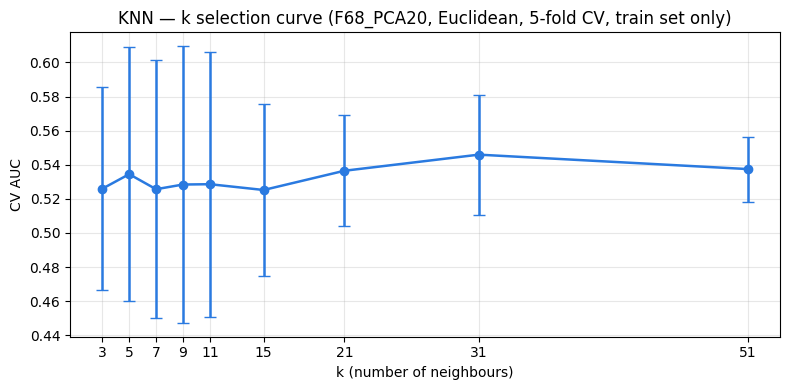

✅ KNN block complete.


In [51]:
cv_results_knn = {}
best_pipes_knn = {}

param_grid_knn = {
    'clf__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31],
    'clf__metric'     : ['euclidean', 'manhattan'],
    'clf__weights'    : ['uniform', 'distance']
}

for feat_name, X_tr in X_train_sets.items():
    key = f'KNN_{feat_name}'

    # Notice we don't need to add PCA here, because make_pipe() from Block 3 already does it!
    pipe = make_pipe(KNeighborsClassifier())

    gs = GridSearchCV(
        pipe, param_grid_knn,
        cv      = cv,
        scoring = 'roc_auc',
        n_jobs  = -1,
        refit   = True
    )
    gs.fit(X_tr, y_train)

    cv_res = cross_validate(
        gs.best_estimator_, X_tr, y_train,
        cv=cv, scoring=SCORING, return_train_score=False
    )

    cv_results_knn[key] = cv_res
    best_pipes_knn[key] = gs.best_estimator_

    print(f'KNN — {feat_name}')
    print(f'  Best params : {gs.best_params_}')
    print(f'  CV AUC  : {cv_res["test_roc_auc"].mean():.3f} ± {cv_res["test_roc_auc"].std():.3f}')
    print(f'  CV Acc  : {cv_res["test_accuracy"].mean():.3f} ± {cv_res["test_accuracy"].std():.3f}')
    print(f'  CV Bal  : {cv_res["test_balanced_accuracy"].mean():.3f} ± {cv_res["test_balanced_accuracy"].std():.3f}')
    print(f'  CV Sens : {cv_res["test_sensitivity"].mean():.3f} ± {cv_res["test_sensitivity"].std():.3f}')
    print()

# ── k vs. CV-AUC plot (F68_PCA20, Euclidean, uniform) ───────────────
# ---> FIXED: Changed from 'F8_confirmed' to 'F68_PCA20'
feat_name = 'F68_PCA20'
X_tr = X_train_sets[feat_name]

k_vals = [3, 5, 7, 9, 11, 15, 21, 31, 51]
auc_means, auc_stds = [], []

for k in k_vals:
    # We still use make_pipe here so that PCA is correctly applied during the K-scan
    pipe_k = make_pipe(KNeighborsClassifier(n_neighbors=k, metric='euclidean'))
    res = cross_validate(pipe_k, X_tr, y_train,
                         cv=cv, scoring='roc_auc')
    auc_means.append(res['test_score'].mean())
    auc_stds.append(res['test_score'].std())

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(k_vals, auc_means, yerr=auc_stds, fmt='o-',
            color='#2A7AE0', capsize=4, linewidth=1.8)
ax.set_xlabel('k (number of neighbours)')
ax.set_ylabel('CV AUC')
ax.set_title(f'KNN — k selection curve ({feat_name}, Euclidean, {N_SPLITS}-fold CV, train set only)')
ax.set_xticks(k_vals)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('knn_k_selection_curve.png', dpi=120, bbox_inches='tight')
plt.show()

print('✅ KNN block complete.')

---
## Block 7 — Gaussian Naïve Bayes

Naïve Bayes assumes feature independence given the class — a strong assumption
given that cortical thickness regions are correlated. It serves as a fast probabilistic
baseline.  
`var_smoothing` is the one hyperparameter tuned.

In [52]:
cv_results_nb = {}
best_pipes_nb = {}

param_grid_nb = {
    'clf__var_smoothing': np.logspace(-12, -1, 20)
}

for feat_name, X_tr in X_train_sets.items():
    key = f'NB_{feat_name}'

    pipe = make_pipe(GaussianNB())

    gs = GridSearchCV(
        pipe, param_grid_nb,
        cv      = cv,
        scoring = 'roc_auc',
        n_jobs  = -1,
        refit   = True
    )
    gs.fit(X_tr, y_train)

    cv_res = cross_validate(
        gs.best_estimator_, X_tr, y_train,
        cv=cv, scoring=SCORING, return_train_score=False
    )

    cv_results_nb[key] = cv_res
    best_pipes_nb[key] = gs.best_estimator_

    print(f'Naïve Bayes — {feat_name}')
    print(f'  Best var_smoothing : {gs.best_params_["clf__var_smoothing"]:.2e}')
    print(f'  CV AUC  : {cv_res["test_roc_auc"].mean():.3f} ± {cv_res["test_roc_auc"].std():.3f}')
    print(f'  CV Acc  : {cv_res["test_accuracy"].mean():.3f} ± {cv_res["test_accuracy"].std():.3f}')
    print(f'  CV Bal  : {cv_res["test_balanced_accuracy"].mean():.3f} ± {cv_res["test_balanced_accuracy"].std():.3f}')
    print(f'  CV Sens : {cv_res["test_sensitivity"].mean():.3f} ± {cv_res["test_sensitivity"].std():.3f}')
    print()

print('✅ Naïve Bayes block complete.')

Naïve Bayes — F68_PCA20
  Best var_smoothing : 1.83e-03
  CV AUC  : 0.574 ± 0.026
  CV Acc  : 0.545 ± 0.022
  CV Bal  : 0.540 ± 0.022
  CV Sens : 0.339 ± 0.051

✅ Naïve Bayes block complete.


---
## Block 8 — Majority Voting Ensemble

A **soft-voting** ensemble averages the predicted class probabilities
from all four classifiers (SVM-linear, SVM-RBF, CART, KNN, NB) before deciding.
This is preferred over hard voting when classifiers are calibrated and
we care about ranking (AUC).

The component classifiers are the **best-parameter pipelines** found in Blocks 4–7
(trained on the full training set already via `GridSearchCV(refit=True)`).

We evaluate the ensemble with another `cross_validate` pass on the train set,
then freeze for test evaluation in Block 9.

In [53]:
cv_results_vote = {}
best_pipes_vote = {}

for feat_name, X_tr in X_train_sets.items():

    # Collect best estimator for each algorithm for this feature set
    estimators = []
    for prefix, store in [
        ('SVM_linear', best_pipes_svm),
        ('SVM_rbf',    best_pipes_svm),
        ('CART',       best_pipes_cart),
        ('KNN',        best_pipes_knn),
        ('NB',         best_pipes_nb),
    ]:
        k = f'{prefix}_{feat_name}'
        if k in store:
            estimators.append((prefix, store[k]))

    if len(estimators) < 2:
        print(f'Not enough estimators for {feat_name}, skipping.')
        continue

    voter = VotingClassifier(
        estimators = estimators,
        voting     = 'soft',     # average probabilities
        n_jobs     = -1
    )

    # CV on train set only
    cv_res = cross_validate(
        voter, X_tr, y_train,
        cv=cv, scoring=SCORING, return_train_score=False
    )

    # Fit on full train for test evaluation
    voter.fit(X_tr, y_train)

    key = f'Vote_{feat_name}'
    cv_results_vote[key] = cv_res
    best_pipes_vote[key] = voter

    print(f'Soft-Voting Ensemble — {feat_name}')
    print(f'  Components: {[name for name, _ in estimators]}')
    print(f'  CV AUC  : {cv_res["test_roc_auc"].mean():.3f} ± {cv_res["test_roc_auc"].std():.3f}')
    print(f'  CV Acc  : {cv_res["test_accuracy"].mean():.3f} ± {cv_res["test_accuracy"].std():.3f}')
    print(f'  CV Bal  : {cv_res["test_balanced_accuracy"].mean():.3f} ± {cv_res["test_balanced_accuracy"].std():.3f}')
    print(f'  CV Sens : {cv_res["test_sensitivity"].mean():.3f} ± {cv_res["test_sensitivity"].std():.3f}')
    print()

print('✅ Voting ensemble block complete.')

Soft-Voting Ensemble — F68_PCA20
  Components: ['SVM_linear', 'SVM_rbf', 'CART', 'KNN', 'NB']
  CV AUC  : 0.581 ± 0.027
  CV Acc  : 0.561 ± 0.017
  CV Bal  : 0.557 ± 0.016
  CV Sens : 0.402 ± 0.019

✅ Voting ensemble block complete.


---
## Block 9 — Final Test-Set Evaluation

**This is the only block that accesses `df_test` / `X_test_sets`.**

Each best pipeline (fitted on all training data) is evaluated exactly **once** on the
held-out test set. This provides an unbiased estimate of generalisation performance.

In [54]:
# ── Collect all best pipelines ───────────────────────────────
all_pipes = {}
all_pipes.update(best_pipes_svm)
all_pipes.update(best_pipes_cart)
all_pipes.update(best_pipes_knn)
all_pipes.update(best_pipes_nb)
all_pipes.update(best_pipes_vote)

test_rows = []

print('🔓 TEST SET ACCESSED')
print('='*70)

for key, pipe in sorted(all_pipes.items()):
    # Determine which feature set this model uses
    feat_name = None
    for fn in FEATURE_SETS.keys():
        if key.endswith(fn):
            feat_name = fn
            break
    if feat_name is None:
        continue

    X_te = X_test_sets[feat_name]

    y_pred  = pipe.predict(X_te)
    y_proba = pipe.predict_proba(X_te)[:, 0]   # P(ASD)

    acc   = accuracy_score(y_test, y_pred)
    bal   = balanced_accuracy_score(y_test, y_pred)
    auc_v = roc_auc_score((y_test == 1).astype(int), y_proba)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn_c, tp = cm.ravel()
    sens = tp / (tp + fn_c) if (tp + fn_c) > 0 else np.nan
    spec = tn / (tn + fp)  if (tn + fp)  > 0 else np.nan
    f1   = 2*tp / (2*tp + fp + fn_c) if (2*tp + fp + fn_c) > 0 else np.nan

    row = {
        'Model'       : key,
        'Features'    : feat_name,
        'Accuracy'    : round(acc,  3),
        'Bal_Accuracy': round(bal,  3),
        'AUC'         : round(auc_v, 3),
        'Sensitivity' : round(sens, 3),
        'Specificity' : round(spec, 3),
        'F1'          : round(f1,  3),
    }
    test_rows.append(row)
    print(f'{key:<40} AUC={auc_v:.3f}  Acc={acc:.3f}  Sens={sens:.3f}  Spec={spec:.3f}')

df_results = pd.DataFrame(test_rows).sort_values('AUC', ascending=False).reset_index(drop=True)
print()
print('=== FINAL TEST-SET COMPARISON TABLE ===')
print(df_results.to_string(index=False))
df_results.to_csv('classification_test_results.csv', index=False)
print('\nSaved → classification_test_results.csv')

🔓 TEST SET ACCESSED
CART_F68_PCA20                           AUC=0.549  Acc=0.537  Sens=0.538  Spec=0.535
KNN_F68_PCA20                            AUC=0.542  Acc=0.522  Sens=0.755  Spec=0.273
NB_F68_PCA20                             AUC=0.578  Acc=0.561  Sens=0.774  Spec=0.333
SVM_linear_F68_PCA20                     AUC=0.592  Acc=0.595  Sens=0.774  Spec=0.404
SVM_rbf_F68_PCA20                        AUC=0.546  Acc=0.517  Sens=0.632  Spec=0.394
Vote_F68_PCA20                           AUC=0.565  Acc=0.541  Sens=0.736  Spec=0.333

=== FINAL TEST-SET COMPARISON TABLE ===
               Model  Features  Accuracy  Bal_Accuracy   AUC  Sensitivity  Specificity    F1
SVM_linear_F68_PCA20 F68_PCA20     0.595         0.589 0.592        0.774        0.404 0.664
        NB_F68_PCA20 F68_PCA20     0.561         0.553 0.578        0.774        0.333 0.646
      Vote_F68_PCA20 F68_PCA20     0.541         0.535 0.565        0.736        0.333 0.624
      CART_F68_PCA20 F68_PCA20     0.537         0.

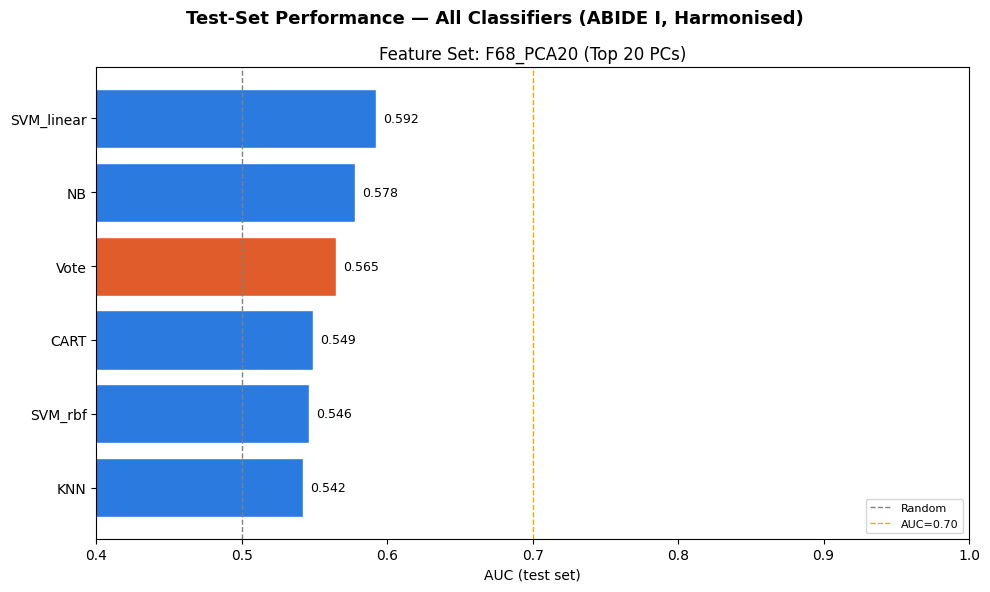

In [55]:
# ── Figure 1: AUC comparison bar chart (Updated for PCA) ──────────
fig, ax = plt.subplots(figsize=(10, 6)) # Changed to a single plot
fig.suptitle('Test-Set Performance — All Classifiers (ABIDE I, Harmonised)',
             fontsize=13, fontweight='bold')

feat = 'F68_PCA20' # Looking for your new PCA features
sub = df_results[df_results.Features == feat].sort_values('AUC', ascending=True)

if len(sub) > 0:
    # Color the Voting classifier orange, others blue
    colors_bar = ['#E05C2A' if 'Vote' in m else '#2A7AE0' for m in sub.Model]
    
    # Remove the feature tag from the model name for a cleaner Y-axis
    clean_model_names = sub.Model.str.replace(f'_{feat}', '', regex=False)
    
    bars = ax.barh(clean_model_names, sub.AUC, color=colors_bar, edgecolor='white')
    ax.axvline(0.5, color='grey', linestyle='--', linewidth=1, label='Random')
    ax.axvline(0.7, color='orange', linestyle='--', linewidth=1, label='AUC=0.70')
    ax.set_xlim(0.4, 1.0)
    ax.set_xlabel('AUC (test set)')
    ax.set_title(f'Feature Set: {feat} (Top 20 PCs)')
    
    for bar, val in zip(bars, sub.AUC):
        ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
                         f'{val:.3f}', va='center', fontsize=9)
    ax.legend(fontsize=8, loc='lower right')
else:
    print(f"Warning: No data found for feature set '{feat}' in df_results.")

plt.tight_layout()
plt.savefig('test_auc_comparison.png', dpi=130, bbox_inches='tight')
plt.show()

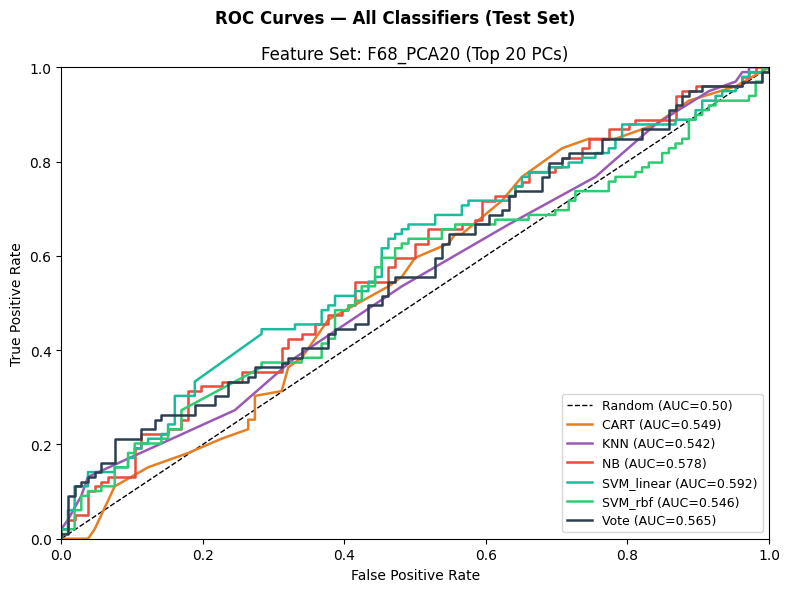

In [ ]:
# ── Figure 2: ROC curves for all models (Updated for PCA) ──────
fig, ax = plt.subplots(figsize=(8, 6)) # Changed to a single plot
fig.suptitle('ROC Curves — All Classifiers (Test Set)',
             fontsize=12, fontweight='bold')

algo_colors = {
    'SVM_linear': '#1abc9c',
    'SVM_rbf'   : '#2ecc71',
    'CART'      : '#e67e22',
    'KNN'       : '#9b59b6',
    'NB'        : '#e74c3c',
    'Vote'      : '#2c3e50',
}

feat = 'F68_PCA20' # Looking for your new PCA features

# Draw the random baseline
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC=0.50)')

# Loop through all trained pipelines and plot the ones that use our PCA features
for key, pipe in sorted(all_pipes.items()):
    if not key.endswith(feat):
        continue
    
    X_te  = X_test_sets[feat]
    y_proba = pipe.predict_proba(X_te)[:, 0] # Probabilities for the positive class (ASD)
    fpr, tpr, _ = roc_curve((y_test == 1).astype(int), y_proba)
    auc_v = auc(fpr, tpr)

    # Clean up the name for the legend
    algo = key.replace(f'_{feat}', '')
    color = next((v for k, v in algo_colors.items() if algo.startswith(k)), '#555')
    
    ax.plot(fpr, tpr, linewidth=1.8, color=color,
            label=f'{algo} (AUC={auc_v:.3f})')

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title(f'Feature Set: {feat} (Top 20 PCs)')
ax.legend(fontsize=9, loc='lower right')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig('roc_curves_all_classifiers.png', dpi=130, bbox_inches='tight')
plt.show()

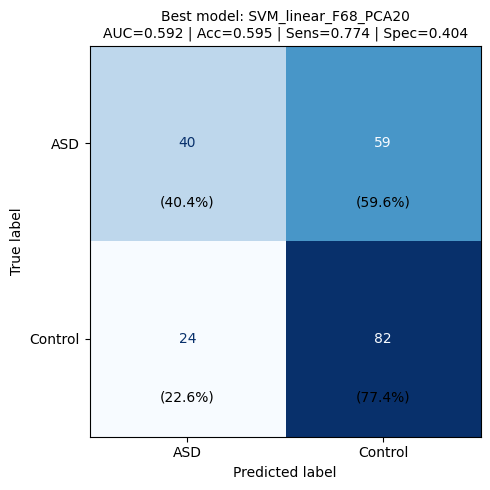

              precision    recall  f1-score   support

         ASD       0.62      0.40      0.49        99
     Control       0.58      0.77      0.66       106

    accuracy                           0.60       205
   macro avg       0.60      0.59      0.58       205
weighted avg       0.60      0.60      0.58       205



In [57]:
# ── Figure 3: Confusion matrices for best AUC model ─────────
best_row = df_results.iloc[0]
best_key  = best_row.Model
best_feat = best_row.Features

best_pipe = all_pipes[best_key]
X_te      = X_test_sets[best_feat]
y_pred    = best_pipe.predict(X_te)

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(cm, display_labels=['ASD', 'Control'])
disp.plot(ax=ax, colorbar=False, cmap='Blues')

tn, fp, fn_c, tp = cm.ravel()
total = cm.sum()
for i in range(2):
    for j in range(2):
        pct = cm[i, j] / cm[i].sum() * 100
        ax.text(j, i + 0.32, f'({pct:.1f}%)', ha='center', fontsize=10)

sens = tp / (tp + fn_c)
spec = tn / (tn + fp)
ax.set_title(
    f'Best model: {best_key}\n'
    f'AUC={best_row.AUC:.3f} | Acc={best_row.Accuracy:.3f} | '
    f'Sens={sens:.3f} | Spec={spec:.3f}',
    fontsize=10
)
plt.tight_layout()
#plt.savefig('confusion_best_model.png', dpi=130, bbox_inches='tight')
plt.show()
print(classification_report(y_test, y_pred, target_names=['ASD', 'Control']))